# Spotify Recommendation Engine

## Objective
Build a reusable content-based nearest-neighbor recommender and evaluate musical coherence honestly in the absence of listener feedback.

## Dataset overview
The source is Yamac Eren Ay's [Spotify Dataset 1921–2020, 600k+ Tracks](https://www.kaggle.com/datasets/yamaerenay/spotify-dataset-19212020-600k-tracks), version 1.
The actual release-year range is audited below rather than inferred from the title. This is a historical catalog snapshot with track metadata, Spotify audio descriptors, and popularity (0–100). It has no track-level genre, album, listener histories, or contemporaneous chart labels.

Run `python scripts/download_data.py` and `python scripts/prepare_data.py` first. Every notebook runs independently from the project root. Source hashes and cleaning counts live in `data/processed/quality_report.json`.

## Imports

In [1]:
from pathlib import Path
import json
import platform
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

RANDOM_STATE = 42
ROOT = Path.cwd()
if not (ROOT / "scripts/prepare_data.py").exists():
    raise RuntimeError("Open Jupyter from the project root.")
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
pd.set_option("display.max_columns", 15)
assert Path(sys.prefix).name == "spotify", "Select the Python (spotify) kernel."
display(Markdown(f"**Runtime:** Python {platform.python_version()} · spotify environment"))
AUDIO_FEATURES = ["danceability", "energy", "valence", "acousticness",
                  "instrumentalness", "speechiness", "liveness", "loudness", "tempo"]

**Runtime:** Python 3.14.7 · spotify environment

## Data loading and cleaning

In [2]:
tracks = pd.read_parquet(ROOT / "data/processed/tracks.parquet")
quality = json.loads((ROOT / "data/processed/quality_report.json").read_text())
display(pd.Series({"raw_rows": quality["raw_rows"],
                   "processed_rows": len(tracks),
                   "first_year": quality["year_min"], "last_year": quality["year_max"],
                   "repeated_artist_title_rows": quality["repeated_artist_title_rows"]}, name="Data audit"))
assert tracks.id.is_unique

raw_rows                      586672
processed_rows                586601
first_year                      1900
last_year                       2021
repeated_artist_title_rows     62393
Name: Data audit, dtype: int64

Shared preparation removes exact duplicates and repeated Spotify IDs, and drops rows without usable identity. Invalid numeric values become missing; unknown zero tempo becomes missing. Dates keep their original precision in `release_date`, with a derived year for grouping. Long recordings are flagged, not arbitrarily deleted. Unicode names are retained. Distinct IDs with the same artist/title remain in the shared data because editions can differ; modeling and recommendation apply stricter deduplication below. Unobserved recordings cannot be identified without acoustic fingerprints.

## Feature engineering and methodology
Keep one edition per artist/title, selecting the first source occurrence without ranking by popularity. Use standardized audio descriptors and log duration; logging reduces the influence of very long recordings. Median imputation handles unknown tempo. Valence is deliberately withheld from retrieval for a later proxy check. No popularity, year, or artist identifier enters similarity.

Cosine similarity compares the direction of standardized feature vectors. A value of 1 indicates matching directions; 0 means orthogonal; negative values are possible. Here directions represent deviations from catalog-average sound. Nearest-neighbor search retrieves the largest cosine similarities without materializing an all-pairs matrix. It describes sound-profile resemblance, not listener preference or probability of enjoyment.

In [3]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits

catalog = tracks.drop_duplicates("recording_group").reset_index(drop=True).copy()
catalog["log_duration"] = np.log1p(catalog.duration_min)
recommendation_features = [feature for feature in AUDIO_FEATURES if feature != "valence"] + ["log_duration"]
preprocessor = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())
feature_matrix = preprocessor.fit_transform(catalog[recommendation_features])
neighbors = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=1).fit(feature_matrix)
id_to_position = pd.Series(catalog.index, index=catalog.id).to_dict()

## Reusable recommendation function
Query by unique Spotify ID to avoid ambiguous titles. The function excludes the seed, suppresses same-title editions, and optionally limits results to other primary artists. It validates inputs and returns identifiers so results remain auditable.

In [4]:
def recommend_tracks(track_id, n=10, different_artist=True):
    if track_id not in id_to_position:
        raise ValueError("Unknown track ID. Search the catalog for a retained edition first.")
    if isinstance(n, bool) or not isinstance(n, int) or not 1 <= n <= 50:
        raise ValueError("n must be an integer between 1 and 50.")
    position = id_to_position[track_id]
    seed = catalog.iloc[position]
    candidate_count = min(len(catalog), max(100, n * 20))
    while True:
        with threadpool_limits(limits=4):
            distances, positions = neighbors.kneighbors(feature_matrix[position:position+1], n_neighbors=candidate_count)
        result = catalog.iloc[positions[0]].copy()
        result["similarity"] = np.clip(1 - distances[0], -1, 1)
        keep = result.id.ne(track_id) & result.name.str.casefold().ne(seed["name"].casefold())
        if different_artist:
            keep &= result.primary_artist_id.ne(seed.primary_artist_id)
        result = result.loc[keep].head(n)
        if len(result) >= n or candidate_count == len(catalog):
            break
        candidate_count = min(len(catalog), candidate_count * 2)
    return result[["id", "name", "artist", "year", "similarity", "energy", "acousticness", "valence"]]

examples = []
for title in ["Blinding Lights", "Bohemian Rhapsody", "Take Five"]:
    matches = catalog.loc[catalog.name.str.casefold().eq(title.casefold())]
    seed = matches.sort_values("popularity", ascending=False).iloc[0]
    examples.append(seed.id)
    display(Markdown(f"### {seed['name']} — {seed.artist}\nSeed ID: `{seed.id}`"))
    display(recommend_tracks(seed.id, n=5).round(3))

### Blinding Lights — The Weeknd
Seed ID: `0VjIjW4GlUZAMYd2vXMi3b`

,id,name,artist,year,similarity,energy,acousticness,valence
442331,483bQv3IAEM9oGrhBrQeFm,Teach Me About Dying,Holy Holy,2019.0,0.995,0.721,0.000,0.346
79513,7Lmwj2fe8MpGXypOuLGO2C,Made in America,Toby Keith,2011.0,0.994,0.701,0.051,0.376
242942,6IW2MfDUE12EAwBIgpUFsZ,Protože to nevzdám,Olga Lounova; Anna Šulcová; Bára Basiková; Dav...,2019.0,0.993,0.719,0.005,0.178
162427,6Bj2EIPJfNv96wY8fCg5eC,Tykkään susta niin että halkeen,Juha Tapio,2013.0,0.993,0.721,0.014,0.768
480217,4TbBexJ8gwjFvd1J6PEgjE,Vymlaceny entry,Pokáč,2017.0,0.993,0.719,0.104,0.521


### Bohemian Rhapsody — Queen
Seed ID: `3z8h0TU7ReDPLIbEnYhWZb`

,id,name,artist,year,similarity,energy,acousticness,valence
487624,6vtoORrRmnWySqDPvtOEnu,Ingli Puudutus - Live,Terminaator,2006.0,0.981,0.380,0.318,0.134
365483,0GTSqpAbGAnsNBZgQhaQS3,Seperti Yang Kau Ingini,Nikita,2004.0,0.981,0.353,0.283,0.095
104119,3pE1kw5TggEb1erG1hAsXJ,All I Need Is You,Hillsong UNITED,2005.0,0.980,0.325,0.128,0.082
106540,7nLL5UrsXYHVWv2DnXBtud,Good Good Father - Live,Casting Crowns,2015.0,0.975,0.420,0.232,0.170
395148,2crjmyGUfpWOeOPAnTqCN6,Alfa e Ômega,Marine Friesen,2016.0,0.973,0.386,0.115,0.159


### Take Five — The Dave Brubeck Quartet
Seed ID: `1YQWosTIljIvxAgHWTp7KP`

,id,name,artist,year,similarity,energy,acousticness,valence
492873,5UTNZdfGwc7gdD6Rj2yybB,休みの日,JUN SKY WALKER(S),1991.0,0.996,0.344,0.524,0.259
51581,18AXbzPzBS8Y3AkgSxzJPb,In The Air Tonight - 2015 Remastered,Phil Collins,1981.0,0.996,0.239,0.551,0.298
260361,6Kfoj2DCFMVXiutjYOhku3,Take Five - Instrumental,Dave Brubeck,2007.0,0.995,0.292,0.563,0.604
449253,2pE8dUPeueXKizEyiPtE1p,In The Air Tonight,Phil Collins,2014.0,0.994,0.234,0.532,0.316
51909,6MjfEIHOMW6MaDO3LpFcmW,In the Air Tonight - 2015 Remaster,Phil Collins,1981.0,0.994,0.238,0.503,0.336


Compare energy and acousticness in each result, and listen if access is available. Similar numerical profiles can have different harmony, instrumentation, language, and cultural context. Filtering another primary artist encourages discovery but cannot remove every shared collaborator.

## Evaluation: a withheld-feature proxy
There are no relevance judgments, playlist membership labels, or user events, so accuracy and recall would be invented. Instead, draw 80 seeded query tracks and compare absolute **valence** differences for their top five recommendations against five randomly drawn eligible tracks. Valence was excluded from retrieval. Lower differences suggest coherence on one related musical descriptor, not personalization quality. A paired bootstrap over query-level differences estimates a conditional 95% interval for improvement over random. The proxy is imperfect because audio descriptors correlate.

catalog_rows               524208.000000
queries                        80.000000
recommended_valence_gap         0.191272
random_valence_gap              0.318480
improvement_ci_low              0.095434
improvement_ci_high             0.157497
dtype: float64

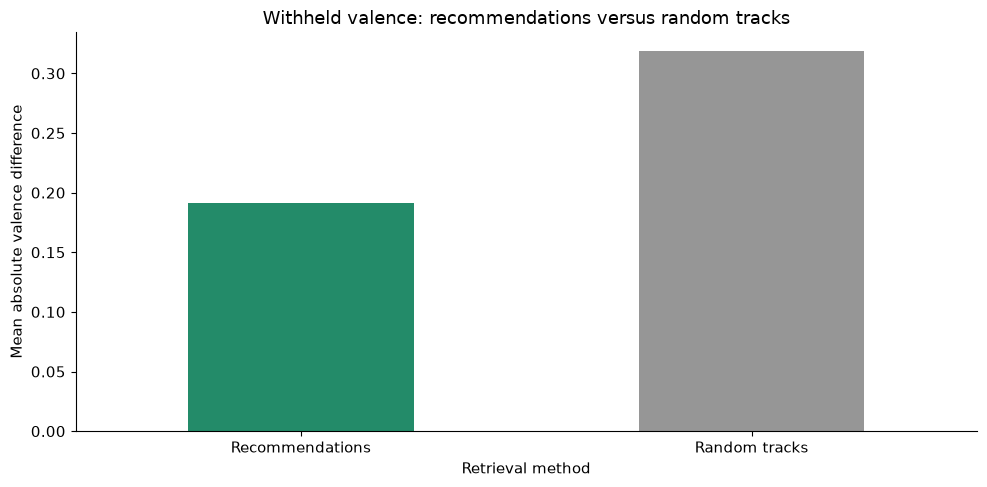

**Proxy result:** The average reduction in valence difference is **0.127**, with a query-bootstrap 95% interval **[0.095, 0.157]**. This is a descriptor-coherence result, not a recommendation accuracy score.

In [5]:
rng = np.random.default_rng(42)
query_positions = rng.choice(len(catalog), size=80, replace=False)
evaluation = []
for position in query_positions:
    seed = catalog.iloc[position]
    recommendations = recommend_tracks(seed.id, n=5)
    eligible = catalog.loc[catalog.primary_artist_id.ne(seed.primary_artist_id) & catalog.name.str.casefold().ne(seed["name"].casefold())]
    random_tracks = eligible.iloc[rng.choice(len(eligible), size=5, replace=False)]
    evaluation.append({"recommended_gap": float((recommendations.valence-seed.valence).abs().mean()),
                       "random_gap": float((random_tracks.valence-seed.valence).abs().mean())})
evaluation = pd.DataFrame(evaluation).dropna()
improvements = (evaluation.random_gap - evaluation.recommended_gap).to_numpy()
bootstrap = np.array([rng.choice(improvements, size=len(improvements), replace=True).mean() for _ in range(2000)])
interval = np.quantile(bootstrap, [0.025, 0.975])
summary = {"catalog_rows": len(catalog), "queries": len(evaluation),
           "recommended_valence_gap": float(evaluation.recommended_gap.mean()),
           "random_valence_gap": float(evaluation.random_gap.mean()),
           "improvement_ci_low": float(interval[0]), "improvement_ci_high": float(interval[1])}
display(pd.Series(summary))
ax = evaluation.mean().rename(index={"recommended_gap": "Recommendations", "random_gap": "Random tracks"}).plot.bar(rot=0, color=["#238b69", "#969696"])
ax.set(title="Withheld valence: recommendations versus random tracks", xlabel="Retrieval method", ylabel="Mean absolute valence difference")
plt.tight_layout()
plt.savefig(REPORTS / "03_proxy.png", dpi=120)
plt.show()
(REPORTS / "recommendation_metrics.json").write_text(json.dumps(summary, indent=2))
assert examples[0] not in recommend_tracks(examples[0], 5).id.tolist()
try:
    recommend_tracks("not-a-track")
except ValueError:
    pass
else:
    raise AssertionError("Unknown IDs must be rejected.")
display(Markdown(f"**Proxy result:** The average reduction in valence difference is **{improvements.mean():.3f}**, with a query-bootstrap 95% interval **[{interval[0]:.3f}, {interval[1]:.3f}]**. This is a descriptor-coherence result, not a recommendation accuracy score."))

## Interpretation, limitations, and conclusion
Content matching works without user history and makes the retrieval criteria inspectable. It cannot infer personal taste, novelty preferences, or context, and it can repeatedly return similar sounds. Scaled cosine similarity emphasizes relative feature patterns and can behave unintuitively near the mean vector. Brute-force query cost grows with catalog size; approximate search may be useful at larger scale. The current API and proxy remain deterministic for this snapshot. A stronger evaluation would collect blind listener judgments with an explicit diversity and novelty rubric, then test against a popularity baseline and alternative distance metrics.